# Runtime figures — section 4.3

Load the saved eight-method JAX study without repeating integrations. This notebook shares the calculation notebook's study prefix and run identifier. Missing local results are recovered from B2 and checked against their SHA-256 manifest. Local solution archives are checked before analysis.

One chart shows the first invocation separately from the median and minimum–maximum range of three later invocations. Its lower axis gives seconds and its upper axis divides those same measurements by the fastest cached median (RK2); both axes are logarithmic and all markers and interval endpoints use the same fixed denominator. The ranges describe these repetitions, not confidence intervals. Results concern the recorded CPU environment, particle set and fixed step, without an accuracy comparison or a general method ranking.

All figure text is French, as required for the thesis. The exported PDF, PNG and JSON provenance are saved under `TFM_redaccion/figuras/`. Re-running this notebook only loads data and redraws the combined figure.


In [1]:
from pathlib import Path
import json
from IPython.display import display, Image

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/studies/method_timings.py").exists())
RUN_ID = "jax-20261118-rho0015-c500"
STUDY_PREFIX = "studies/method_timings"
DIRECTORY = ROOT / "outputs" / STUDY_PREFIX / RUN_ID
BUCKET = f"gc2d_data:gc2d-notebooks-data/{STUDY_PREFIX}/{RUN_ID}"
CYCLES = 500
REPETITIONS = 3


In [2]:
from studies.method_timings_io import recover_study
from visualization.method_timings import summarize, export_figures
if not (DIRECTORY / "timings.json").exists():
    recover_study(BUCKET, DIRECTORY)
summary = summarize(DIRECTORY)
assert summary["study"]["cycles"] == CYCLES
FIGURES = ROOT.parent / "TFM_redaccion/figuras"
paths = export_figures(summary, FIGURES)
for row in summary["rows"]:
    print(f'{row["method"]}: median {row["median_seconds"]:.6f} s; range [{row["minimum_seconds"]:.6f}, {row["maximum_seconds"]:.6f}] s; relative time {row["relative_time"]:.3f}')
print("Fastest cached median:", summary["fastest_method"])


RK2: median 2.164691 s; range [2.137034, 2.284513] s; relative time 1.000
ImplicitMidpoint: median 5.886767 s; range [5.714194, 5.925600] s; relative time 2.719
RK4: median 3.050642 s; range [2.819637, 3.155285] s; relative time 1.409
GaussLegendre4: median 7.656109 s; range [7.651559, 7.755714] s; relative time 3.537
ABBA2Midpoint: median 4.342777 s; range [4.319757, 4.632738] s; relative time 2.006
ABBA2Implicit: median 24.468711 s; range [22.446477, 24.761951] s; relative time 11.304
BM4Midpoint: median 19.328531 s; range [19.239684, 21.751638] s; relative time 8.929
BM4Implicit: median 87.321191 s; range [81.878077, 88.005103] s; relative time 40.339
Fastest cached median: RK2


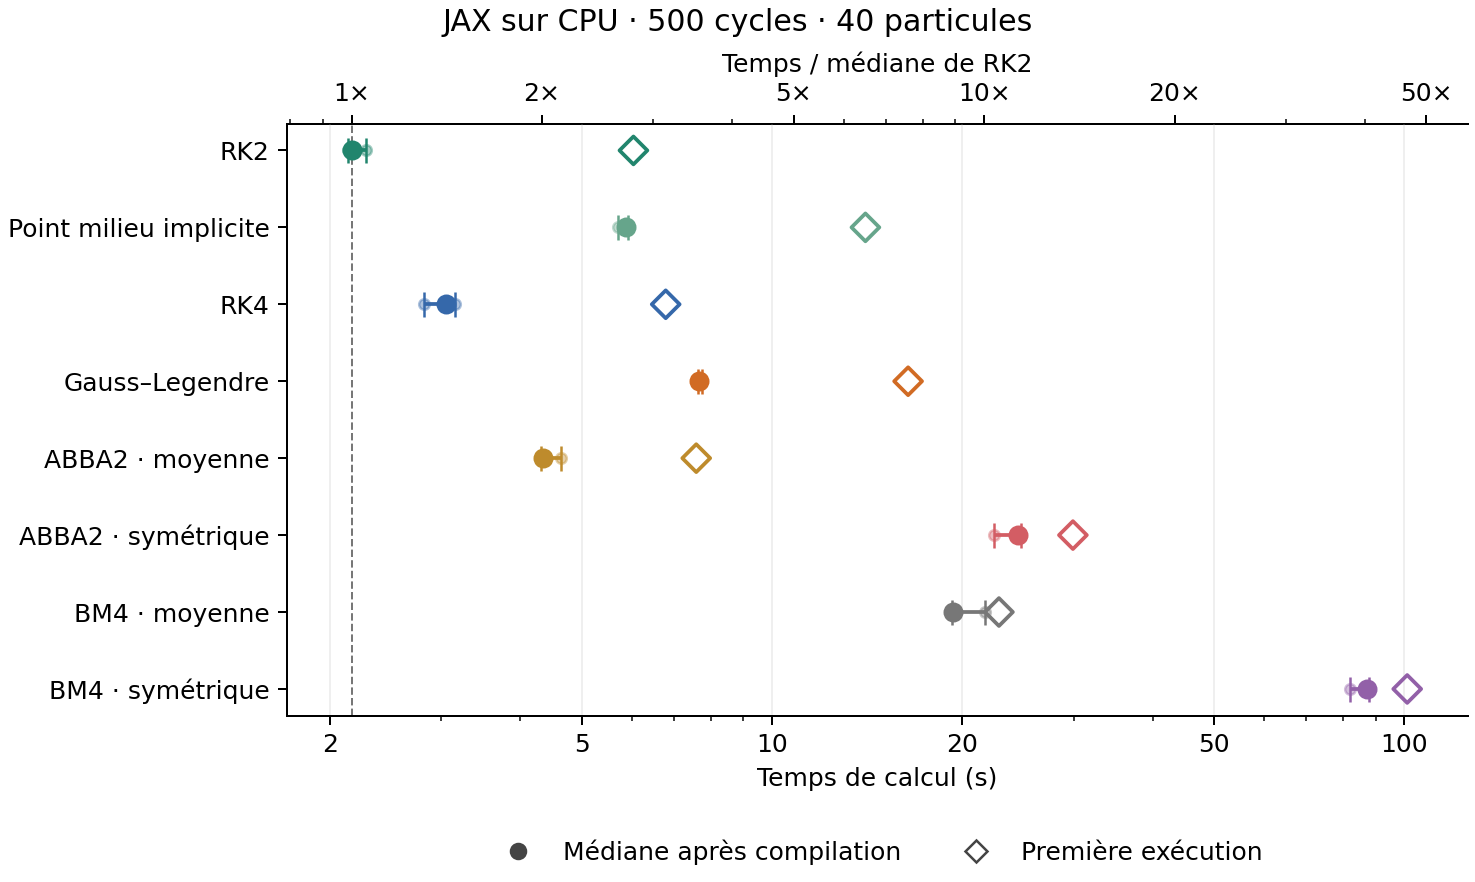

In [3]:
display(Image(filename=str(FIGURES / "comparacion_tiempos_metodos_fr.png")))
